# 04. Сравнение retrieval-моделей с доверительными интервалами

Стадия: retrieval. Модели: популярность (`packages/training/src/training/evaluation/`), item-item (`packages/training/src/training/retrieval/item_knn.py`, ноутбук `03_item_knn.ipynb`), PureSVD (`packages/training/src/training/retrieval/svd.py`, эксперимент E04).

Главная метрика retrieval — `recall@100`: попали ли спрятанные ответы пользователя в 100 лучших кандидатов. Остальные метрики — бонус.

Зачем интервалы: на val всего 173 пользователя, и разница между моделями может оказаться шумом выбора людей. Доверительный интервал показывает, насколько можно верить среднему; **парный** bootstrap для разницы двух моделей показывает, случайна ли эта разница.

Оценка на **val**; test оставляем для финальной проверки после выбора модели и настроек.

## Загрузка и построение моделей

Все модели строятся по train-пользователям. Для item-item и SVD берём вес пользователя `1/sqrt(n)` (лучшая форма по `recall@100` в E02). Для SVD сравниваем три размерности `k`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training.evaluation import protocol, stats
from training.interactions import store
from training.retrieval import popularity
from training.retrieval import als
from training.retrieval import svd as emb
from training.retrieval import item_knn as knn

table, catalog = store.load_interactions()
cases = protocol.build_cases(table, "val")

matrix, train_users, item_ids = knn.build_train_matrix(table, catalog)
histories = knn.build_histories(table, "val", item_ids)  # что val-пользователь уже досмотрел (input)
weights = knn.user_weights(matrix, form=1)  # 1/sqrt(n)

similarity = knn.item_similarity(matrix, weights)
factors = {k: emb.fit_item_factors(matrix, weights, k) for k in (16, 64, 128)}

# E04b: нормировка столбцов на популярность аниме (beta = 0,5 — как косинус)
scales = {beta: emb.column_scale(matrix, weights, beta) for beta in (0.25, 0.5)}
# E05: iALS (implicit), бинарная уверенность, alpha=5 (параметры в packages/training/src/training/retrieval/als.py)
confidence = als.build_confidence_matrix(matrix)
als_models = {f: als.fit_als(confidence, f) for f in (64, 128)}

factors_normalised = {beta: emb.fit_item_factors(matrix, weights, 64, scale=s) for beta, s in scales.items()}

rankers = {
    "popularity": popularity.make_popularity_ranker(popularity.popularity_scores(table)),
    "item_knn": knn.make_item_knn_ranker(similarity, item_ids, histories),
    **{f"svd_k{k}": emb.make_svd_ranker(f, item_ids, histories) for k, f in factors.items()},
    **{f"svd_k64_b{beta}": emb.make_svd_ranker(f, item_ids, histories, scale=scales[beta])
       for beta, f in factors_normalised.items()},
    "svd_k64_b0.25_undo": emb.make_svd_ranker(factors_normalised[0.25], item_ids, histories,
                                              scale=scales[0.25], undo_scale=True),
    **{f"als_f{f}": als.make_als_ranker(model, item_ids, histories) for f, model in als_models.items()},
}
len(cases), list(rankers)

(173,
 ['popularity',
  'item_knn',
  'svd_k16',
  'svd_k64',
  'svd_k128',
  'svd_k64_b0.25',
  'svd_k64_b0.5',
  'svd_k64_b0.25_undo'])

## Метрики по каждому пользователю

`evaluate_per_user` возвращает для каждой модели таблицу «пользователь × метрика»: из неё считаются средние и интервалы. Порядок пользователей у всех моделей одинаковый, это нужно для парного сравнения.

In [2]:
per_user = {name: protocol.evaluate_per_user(ranker, cases, catalog) for name, ranker in rankers.items()}
per_user["svd_k64"].head()

,recall@10,hit_rate@10,ndcg@10,recall@20,hit_rate@20,ndcg@20,recall@100,hit_rate@100,ndcg@100
940,0.160000,1.0,0.272670,0.240000,1.0,0.245766,0.440000,1.0,0.323788
14083,0.176471,1.0,0.930569,0.294118,1.0,0.816397,0.627451,1.0,0.677866
34154,0.200000,1.0,0.936379,0.244444,1.0,0.675678,0.555556,1.0,0.610508
47423,0.045045,1.0,1.000000,0.081081,1.0,0.932500,0.274775,1.0,0.683503
48746,0.098592,1.0,0.788550,0.169014,1.0,0.685595,0.408451,1.0,0.489279


## Среднее и 95% доверительный интервал

Интервал считает `bootstrap_ci`: много раз выбираем пользователей с возвращением и смотрим, как «плавает» среднее. Чем интервал шире, тем меньше можно верить разнице между моделями в пределах интервала.

In [3]:
def summary(metric: str) -> pd.DataFrame:
    rows = {}
    for name, df in per_user.items():
        values = df[metric].to_numpy()
        low, high = stats.bootstrap_ci(values)
        rows[name] = {"среднее": values.mean(), "нижняя": low, "верхняя": high}
    return pd.DataFrame(rows).T


recall100 = summary("recall@100")
recall100.round(4)

,среднее,нижняя,верхняя
popularity,0.3844,0.3502,0.4181
item_knn,0.4777,0.4441,0.5111
svd_k16,0.5786,0.5445,0.6123
svd_k64,0.6181,0.5872,0.6483
svd_k128,0.6196,0.5872,0.6519
svd_k64_b0.25,0.6188,0.5854,0.6500
svd_k64_b0.5,0.4848,0.4447,0.5239
svd_k64_b0.25_undo,0.6206,0.5870,0.6517


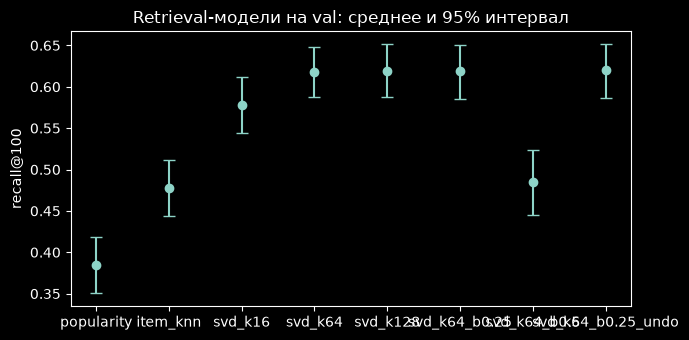

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
errors = [recall100["среднее"] - recall100["нижняя"], recall100["верхняя"] - recall100["среднее"]]
ax.errorbar(recall100.index, recall100["среднее"], yerr=errors, fmt="o", capsize=4)
ax.set_ylabel("recall@100")
ax.set_title("Retrieval-модели на val: среднее и 95% интервал")
plt.tight_layout()

Если интервалы двух моделей не пересекаются, это сильный довод, что разница реальна. Если пересекаются, надёжнее смотреть на парное сравнение ниже: оно точнее, потому что учитывает, что модели оценивались на одних и тех же людях.

## Парное сравнение: случайна ли разница между моделями

Для каждой пары считаем среднюю разницу `recall@100` (первая модель минус вторая) и её 95% интервал. Если интервал целиком выше нуля, первая модель лучше не случайно; если содержит ноль, различие не отличить от шума.

In [5]:
pairs = [
    ("item_knn", "popularity"),
    ("svd_k64", "popularity"),
    ("svd_k64", "item_knn"),
    ("svd_k128", "svd_k64"),
    ("svd_k64", "svd_k16"),
    ("svd_k64_b0.25", "svd_k64"),
    ("svd_k64_b0.5", "svd_k64"),
    ("als_f64", "svd_k64"),
    ("als_f128", "svd_k64"),
    ("als_f128", "als_f64"),
]


def paired_table(metric: str) -> pd.DataFrame:
    rows = []
    for a, b in pairs:
        mean_diff, low, high = stats.paired_bootstrap_diff(per_user[a][metric], per_user[b][metric])
        rows.append({"пара": f"{a} − {b}", "разница": mean_diff, "нижняя": low, "верхняя": high,
                     "значима": bool(low > 0 or high < 0)})
    return pd.DataFrame(rows).set_index("пара")


paired_table("recall@100").round(4)

,разница,нижняя,верхняя,значима
пара,,,,
item_knn − popularity,0.0933,0.0687,0.1177,True
svd_k64 − popularity,0.2338,0.2017,0.2664,True
svd_k64 − item_knn,0.1404,0.1181,0.1656,True
svd_k128 − svd_k64,0.0014,-0.0167,0.0198,False
svd_k64 − svd_k16,0.0396,0.0222,0.0564,True
svd_k64_b0.25 − svd_k64,0.0007,-0.0131,0.0150,False
svd_k64_b0.5 − svd_k64,-0.1333,-0.1649,-0.1044,True


## Бонус: те же сравнения по `ndcg@10` и `hit_rate@10`

Эти метрики относятся к итоговому списку из 10 аниме, а не к retrieval; выводов о retrieval на них не строим.

In [6]:
paired_table("ndcg@10").round(4)

,разница,нижняя,верхняя,значима
пара,,,,
item_knn − popularity,0.1123,0.0731,0.1527,True
svd_k64 − popularity,0.3020,0.2643,0.3399,True
svd_k64 − item_knn,0.1897,0.1560,0.2249,True
svd_k128 − svd_k64,0.0160,-0.0016,0.0334,False
svd_k64 − svd_k16,0.0848,0.0596,0.1113,True
svd_k64_b0.25 − svd_k64,-0.0615,-0.0852,-0.0378,True
svd_k64_b0.5 − svd_k64,-0.3012,-0.3408,-0.2624,True


ДИ показали, что svd очевидно справляется лучше, чем остальные методы, однако разницы между параметрами k=64 и k=128 нет. Так что будем брать svd k = 64.

## E04b: нормировка столбцов на популярность аниме

Идея из item-item: делить на размер аудитории аниме, чтобы хиты не вылезали. В SVD это делается умножением столбцов матрицы на `1/аудитория^beta` перед разложением (`beta = 0,5` — как косинус, `beta = 0,25` мягче); историю пользователя при подсчёте баллов масштабируем так же. `_undo` — вариант, где итоговые баллы возвращены в исходные единицы. Парные сравнения с обычным `svd_k64` выше (`svd_k64_b0.25 − svd_k64`, `svd_k64_b0.5 − svd_k64`). Покрытие относится ко всей выдаче, а не к отдельному пользователю, поэтому интервала для него здесь нет, только значения.

In [7]:
coverage = pd.DataFrame({name: protocol.evaluate(r, cases, catalog) for name, r in rankers.items()})
coverage.loc[["recall@100", "coverage@100", "coverage@10", "ndcg@10"]].round(4).T

,recall@100,coverage@100,coverage@10,ndcg@10
popularity,0.3844,0.0576,0.0095,0.3140
item_knn,0.4777,0.1221,0.0279,0.4263
svd_k16,0.5786,0.1815,0.0432,0.5311
svd_k64,0.6181,0.2373,0.0663,0.6160
svd_k128,0.6196,0.2678,0.0773,0.6320
svd_k64_b0.25,0.6188,0.3527,0.0889,0.5545
svd_k64_b0.5,0.4848,0.6004,0.1325,0.3148
svd_k64_b0.25_undo,0.6206,0.2273,0.0521,0.5549


Результат: мягкая нормировка (beta = 0,25) не ухудшила recall@100, но расширила покрытие кандидатов (0,24 → 0,35); полная косинусная (beta = 0,5) для SVD оказалась слишком сильной (recall@100 падает до 0,485).

## E05: iALS

iALS (неявный ALS, `packages/training/src/training/retrieval/als.py`): просмотр — позитив с уверенностью `alpha · значение клетки` (так считает библиотека `implicit`; у нас бинарная матрица и `alpha = 5`, то есть уверенность 5, все просмотры весят одинаково), пустая клетка — «неизвестно» с уверенностью 1. В исходной статье Hu, Koren, Volinsky уверенность просмотра `1 + alpha · r`; в мини-примере ниже использована именно эта формула (6 у просмотра). Векторы учатся чередованием: при фиксированных векторах аниме точно пересчитываются векторы пользователей и наоборот. Вектор val-пользователя считается по его `input` одним таким шагом (`recalculate_user`). Модели `als_f64` и `als_f128` уже есть в таблицах выше (интервалы, парные сравнения с `svd_k64`, покрытие).

Вывод по E05:

- **iALS лучше SVD по главной метрике retrieval.** `recall@100` у `als_f128` 0,647 против 0,618 у `svd_k64`; парная разница +0,028 с интервалом [0,016; 0,042], значима. У `als_f64` тоже значимый, но меньший выигрыш (+0,015 [0,002; 0,028]); 128 факторов лучше 64 (+0,014 [0,001; 0,027]).
- **По точности топ-10 (бонус) разницы с SVD не видно:** `ndcg@10` `als_f128 − svd_k64` −0,018 [−0,041; 0,003], интервал содержит ноль.
- **Покрытие у iALS выше:** `coverage@100` 0,305 против 0,237 у SVD.
- **Выбор для следующей стадии:** retrieval — `als_f128` (кандидаты для ранжирования). Оговорки: `alpha`, `factors` и вид уверенности подобраны на тех же 173 val-пользователях, выигрыш небольшой (около 3 п.п.); окончательно подтвердить на test.
